# Llegar antes — Modelo predictivo de cobranza preventiva y temprana

**Banco Austral** (entidad ficticia · datos 100% sintéticos)

**Pregunta de negocio:** con la misma capacidad de gestores, ¿cómo evitamos más pérdida en la mora temprana (hasta 90 días)?

**Respuesta que construye este notebook:**

1. Un **modelo preventivo** que predice qué clientes al día van a entrar en mora el mes próximo.
2. Un **modelo temprano** que, para clientes en mora de 1 a 90 días, predice quién va a **rolear** al tramo siguiente y quién se va a **regularizar solo** (self-cure).
3. Una **regla de priorización y canal** que traduce esas probabilidades a pérdida esperada en pesos: el gestor humano va donde más valor evita; el canal digital, al cliente que se cura solo.
4. Un **backtest** que compara esta estrategia contra la gestión tradicional (llamar por días de atraso).

| Sección | Qué hace |
|---|---|
| 1 | Carga y diagnóstico de la cartera |
| 2 | Roll rates (matriz de transición) |
| 3 | Variables de comportamiento |
| 4 | Modelo preventivo |
| 5 | Modelo temprano: roleo y self-cure |
| 6 | De probabilidad a pesos: pérdida esperada |
| 7 | Estrategia y backtest vs gestión tradicional |
| 8 | Lista priorizada del próximo mes |
| 9 | Conclusiones y limitaciones |

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from lightgbm import LGBMClassifier
warnings.filterwarnings("ignore")

RAIZ = Path.cwd()  # todos los archivos del proyecto viven en la misma carpeta
DATA = OUT = IMG = RAIZ

# Identidad visual del proyecto (paleta validada para daltonismo)
AZUL, NARANJA, TINTA, GRIS, GRILLA = "#2A6496", "#C8622A", "#14202B", "#5A6470", "#E4E0D8"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "axes.titlelocation": "left", "font.size": 11, "axes.edgecolor": GRILLA,
    "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS, "axes.titleweight": "bold",
    "axes.titlesize": 13, "axes.titlecolor": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6, "legend.frameon": False,
})
TRAMOS = {0: "Al día", 1: "1-30", 2: "31-60", 3: "61-90", 4: "90+"}
pesos = lambda x: f"$ {x/1e6:,.1f} M".replace(",", "X").replace(".", ",").replace("X", ".")

## 1. Carga y diagnóstico de la cartera

Dos tablas: `clientes` (datos fijos) y `comportamiento_mensual` (una fila por cliente y mes, 18 meses).

In [2]:
cli = pd.read_csv(DATA / "clientes.csv")
p = pd.read_csv(DATA / "comportamiento_mensual.csv").merge(cli, on="cliente_id")
p = p.sort_values(["cliente_id", "mes"]).reset_index(drop=True)
print(f"{cli.shape[0]:,} clientes · {p.shape[0]:,} filas · meses {p.mes.min()} a {p.mes.max()}")
mix = p.groupby("mes")["tramo"].value_counts(normalize=True).unstack().rename(columns=TRAMOS)
(mix * 100).round(1).tail(6)

12,000 clientes · 216,000 filas · meses 2025-04 a 2026-09


tramo,Al día,1-30,31-60,61-90,90+
mes,,,,,
2026-04,89.9,3.4,1.2,0.9,4.6
2026-05,89.4,3.4,1.3,0.8,5.1
2026-06,89.1,3.2,1.3,0.9,5.5
2026-07,88.5,3.4,1.2,0.9,6.1
2026-08,87.9,3.2,1.3,0.9,6.7
2026-09,87.3,3.3,1.3,1.0,7.0


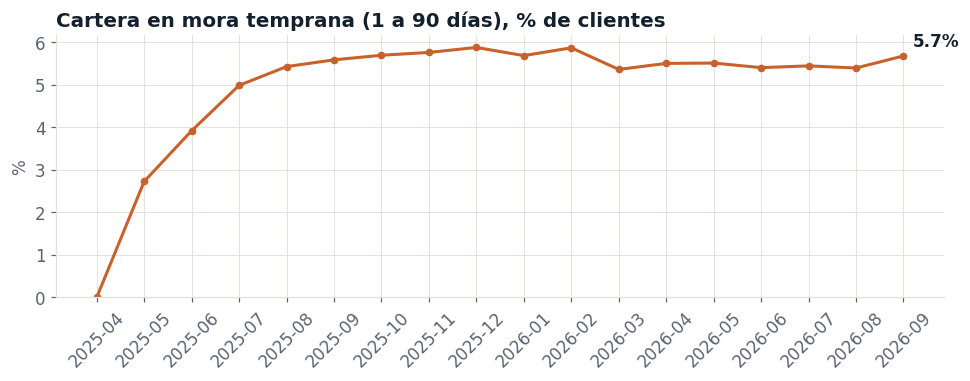

In [3]:
mora_temprana = (mix[["1-30", "31-60", "61-90"]].sum(axis=1) * 100)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(mora_temprana.index, mora_temprana.values, color=NARANJA, lw=2, marker="o", ms=4)
ax.set_title("Cartera en mora temprana (1 a 90 días), % de clientes")
ax.set_ylabel("%"); ax.set_ylim(0, None); ax.tick_params(axis="x", rotation=45)
ax.annotate(f"{mora_temprana.iloc[-1]:.1f}%", (mora_temprana.index[-1], mora_temprana.iloc[-1]),
            textcoords="offset points", xytext=(6, 6), color=TINTA, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG / "01_mora_temprana.png"); plt.show()

## 2. Roll rates: cómo migra la cartera entre tramos

La matriz de transición dice, de cada 100 clientes en un tramo, a dónde van el mes siguiente.
Es la base para medir el problema y, más adelante, para calcular la pérdida esperada (sección 6).

In [4]:
g = p.groupby("cliente_id")
p["mes_idx"] = g.cumcount()
p["tramo_sig"] = g["tramo"].shift(-1)

ENTRENAMIENTO = range(6, 14)   # meses usados para entrenar
FUERA_DE_TIEMPO = range(14, 17) # meses reservados para validar (el modelo nunca los vio)

trans = p[p.mes_idx.isin(ENTRENAMIENTO) & p.tramo_sig.notna()]
M = pd.crosstab(trans.tramo, trans.tramo_sig, normalize="index").reindex(index=range(5), columns=range(5), fill_value=0)
M.loc[4] = [0, 0, 0, 0, 1]  # 90+ pasa a recupero (estado absorbente)
M_vista = (M.iloc[:4] * 100).round(1).rename(index=TRAMOS, columns=TRAMOS)
M_vista

tramo_sig,Al día,1-30,31-60,61-90,90+
tramo,,,,,
Al día,97.2,2.8,0.0,0.0,0.0
1-30,47.9,25.9,26.1,0.0,0.0
31-60,22.1,0.0,28.4,49.4,0.0
61-90,9.4,0.0,0.0,30.8,59.8


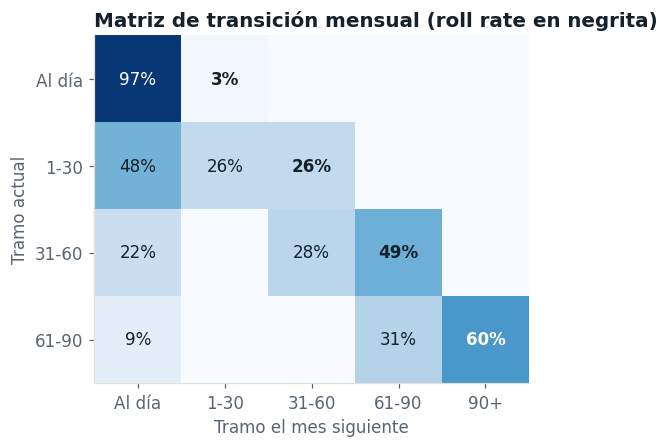

Roll rate por tramo: {'Al día': '2.8%', '1-30': '26.1%', '31-60': '49.4%', '61-90': '59.8%'}
Cura por tramo:      {'1-30': '47.9%', '31-60': '22.1%', '61-90': '9.4%'}


In [5]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
vals = M.iloc[:4].values * 100
ax.imshow(vals, cmap="Blues", vmin=0, vmax=100)
ax.grid(False)
ax.set_xticks(range(5), [TRAMOS[i] for i in range(5)]); ax.set_yticks(range(4), [TRAMOS[i] for i in range(4)])
ax.set_xlabel("Tramo el mes siguiente"); ax.set_ylabel("Tramo actual")
for i in range(4):
    for j in range(5):
        if vals[i, j] > 0.05:
            ax.text(j, i, f"{vals[i,j]:.0f}%", ha="center", va="center",
                    color="white" if vals[i, j] > 55 else TINTA, fontsize=11,
                    fontweight="bold" if j == i + 1 else "normal")
ax.set_title("Matriz de transición mensual (roll rate en negrita)")
plt.tight_layout(); plt.savefig(IMG / "02_matriz_transicion.png"); plt.show()

roll = {TRAMOS[k]: M.loc[k, k + 1] for k in range(4)}
cura = {TRAMOS[k]: M.loc[k, 0] for k in range(1, 4)}
print("Roll rate por tramo:", {k: f"{v:.1%}" for k, v in roll.items()})
print("Cura por tramo:     ", {k: f"{v:.1%}" for k, v in cura.items()})

**Lectura:** la mitad de lo que llega a 31-60 pasa a 61-90, y más de la mitad de 61-90 cae en 90+.
Cada salto de tramo empeora mucho el recupero, por eso conviene actuar en los primeros tramos —o antes.

## 3. Variables de comportamiento

La mora es la *consecuencia*. Lo que queremos captar son las **señales previas**: cambios en el comportamiento
de los últimos 3 a 6 meses. Cada variable tiene una lógica de negocio explicable.

| Variable | Qué capta |
|---|---|
| `corte_sueldo_3m` | Dejó de acreditar el sueldo en los últimos 3 meses |
| `var_saldo_3m` | Caída de saldos en cuentas vs su promedio reciente |
| `utilizacion_tarjeta`, `var_utiliz_3m` | Se "financia" con la tarjeta |
| `deuda_otras_entidades_x_ingreso`, `var_deuda_otras_3m` | Endeudamiento en el resto del sistema |
| `situacion_sistema` | Peor situación en la Central de Deudores (1 a 5) |
| `logins_app`, `var_logins_3m` | Desconexión del banco |
| `anticipo_prom_3m`, `caida_anticipo` | Paga cada vez más sobre la fecha de vencimiento |
| `meses_en_mora_6m`, `max_tramo_6m`, `promesas_incumplidas_6m` | Historial reciente de pago |

In [6]:
def ventana(col, n, fn="mean", desde=1):
    s = g[col].shift(desde)
    return s.groupby(p.cliente_id).transform(lambda x: getattr(x.rolling(n, min_periods=1), fn)())

p["corte_sueldo_3m"] = ((p.acredita_sueldo == 0) & (g["acredita_sueldo"].shift(3) == 1)).astype(int)
p["var_saldo_3m"] = (p.saldo_cuentas / ventana("saldo_cuentas", 3) - 1).clip(-1, 3)
p["var_utiliz_3m"] = p.utilizacion_tarjeta - g["utilizacion_tarjeta"].shift(3)
p["var_deuda_otras_3m"] = p.deuda_otras_entidades_x_ingreso - g["deuda_otras_entidades_x_ingreso"].shift(3)
p["var_logins_3m"] = p.logins_app - ventana("logins_app", 3)
p["anticipo_prom_3m"] = ventana("dias_pago_anticipado", 3, desde=0)
p["caida_anticipo"] = ventana("dias_pago_anticipado", 3) - p.dias_pago_anticipado
p["meses_en_mora_6m"] = (p.tramo > 0).astype(int).groupby(p.cliente_id).transform(lambda x: x.rolling(6, min_periods=1).sum())
p["max_tramo_6m"] = ventana("tramo", 6, "max")
p["promesas_incumplidas_6m"] = p.promesa_incumplida.groupby(p.cliente_id).transform(lambda x: x.rolling(6, min_periods=1).sum())
p["exposicion_x_ingreso"] = p.exposicion / p.ingreso_mensual
p["log_ingreso"] = np.log(p.ingreso_mensual)
p["seg_premium"] = (p.segmento == "Premium").astype(int)
p["seg_plus"] = (p.segmento == "Plus").astype(int)

# Variables objetivo (lo que pasa el mes siguiente)
p["entra_mora"] = (p.tramo_sig >= 1).astype(int)
p["rolea"] = (p.tramo_sig > p.tramo).astype(int)
p["se_cura"] = (p.tramo_sig == 0).astype(int)

COMUNES = ["acredita_sueldo", "corte_sueldo_3m", "var_saldo_3m", "utilizacion_tarjeta", "var_utiliz_3m",
           "deuda_otras_entidades_x_ingreso", "var_deuda_otras_3m", "situacion_sistema", "logins_app",
           "var_logins_3m", "pago_canal_digital", "meses_en_mora_6m", "max_tramo_6m", "exposicion_x_ingreso",
           "log_ingreso", "antiguedad_meses", "edad", "tiene_inversiones", "seg_premium", "seg_plus"]
VARS_PREV = COMUNES + ["anticipo_prom_3m", "caida_anticipo"]
# Nota: "días de atraso" queda afuera a propósito: está casi totalmente explicado por el tramo y, juntos,
# generan pesos con signo engañoso (colinealidad). Un modelo que se explica a un comité no puede tener eso.
VARS_TEMP = COMUNES + ["tramo", "promesas_incumplidas_6m"]

NOMBRES = {
    "acredita_sueldo": "Acredita sueldo", "corte_sueldo_3m": "Cortó acreditación de sueldo",
    "var_saldo_3m": "Variación de saldos (3m)", "utilizacion_tarjeta": "Uso del límite de tarjeta",
    "var_utiliz_3m": "Suba del uso de tarjeta (3m)", "deuda_otras_entidades_x_ingreso": "Deuda en otras entidades",
    "var_deuda_otras_3m": "Suba de deuda en otras entidades", "situacion_sistema": "Situación en el sistema (BCRA)",
    "logins_app": "Ingresos a la app", "var_logins_3m": "Variación de ingresos a la app",
    "pago_canal_digital": "Paga por canal digital", "meses_en_mora_6m": "Meses en mora (6m)",
    "max_tramo_6m": "Peor tramo (6m)", "exposicion_x_ingreso": "Deuda en el banco / ingreso",
    "log_ingreso": "Ingreso", "antiguedad_meses": "Antigüedad", "edad": "Edad", "tiene_inversiones": "Tiene inversiones",
    "seg_premium": "Segmento Premium", "seg_plus": "Segmento Plus", "anticipo_prom_3m": "Días de pago anticipado",
    "caida_anticipo": "Paga cada vez más tarde", "tramo": "Tramo actual", "dias_atraso": "Días de atraso",
    "promesas_incumplidas_6m": "Promesas incumplidas (6m)",
}

base = p[p.tramo_sig.notna()].copy()
prev = base[base.tramo == 0]
temp = base[base.tramo.between(1, 3)]
ent = lambda d: d[d.mes_idx.isin(ENTRENAMIENTO)]
oot = lambda d: d[d.mes_idx.isin(FUERA_DE_TIEMPO)]
print(f"Preventivo: {len(ent(prev)):,} filas de entrenamiento, tasa de entrada {ent(prev).entra_mora.mean():.2%}")
print(f"Temprano:   {len(ent(temp)):,} filas de entrenamiento, roll {ent(temp).rolea.mean():.1%}, cura {ent(temp).se_cura.mean():.1%}")

Preventivo: 87,503 filas de entrenamiento, tasa de entrada 2.78%
Temprano:   5,429 filas de entrenamiento, roll 36.8%, cura 36.0%


**Validación fuera de tiempo:** los modelos se entrenan con 8 meses y se evalúan con los 3 meses siguientes,
que nunca vieron. Es como se usa en la realidad: se entrena con el pasado y se aplica al futuro.

## 4. Modelo preventivo: ¿quién va a entrar en mora el mes próximo?

Dos modelos compiten:

- **Regresión logística** (el *campeón explicable*): cada variable tiene un peso que se puede leer y defender ante un comité.
- **LightGBM** (el *retador*): árboles de decisión potenciados, suele predecir algo mejor pero es menos transparente.

Métricas: **AUC** (0,5 = azar, 1 = perfecto), **Gini** = 2·AUC − 1 y **KS** (máxima separación entre buenos y malos).

In [7]:
def metricas(y, s):
    auc = roc_auc_score(y, s); fpr, tpr, _ = roc_curve(y, s)
    return {"AUC": round(auc, 3), "Gini": round(2 * auc - 1, 3), "KS": round(max(tpr - fpr), 3)}

def entrenar(datos, variables, objetivo):
    X, y = ent(datos)[variables].fillna(0), ent(datos)[objetivo]
    Xo, yo = oot(datos)[variables].fillna(0), oot(datos)[objetivo]
    log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X, y)
    gbm = LGBMClassifier(n_estimators=300, learning_rate=0.04, num_leaves=15, min_child_samples=80,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=7).fit(X, y)
    tabla = pd.DataFrame({
        "Logística · entrenamiento": metricas(y, log.predict_proba(X)[:, 1]),
        "Logística · fuera de tiempo": metricas(yo, log.predict_proba(Xo)[:, 1]),
        "LightGBM · fuera de tiempo": metricas(yo, gbm.predict_proba(Xo)[:, 1]),
    }).T
    return log, gbm, tabla

log_prev, gbm_prev, tabla_prev = entrenar(prev, VARS_PREV, "entra_mora")
tabla_prev

,AUC,Gini,KS
Logística · entrenamiento,0.732,0.464,0.332
Logística · fuera de tiempo,0.734,0.468,0.348
LightGBM · fuera de tiempo,0.728,0.457,0.340


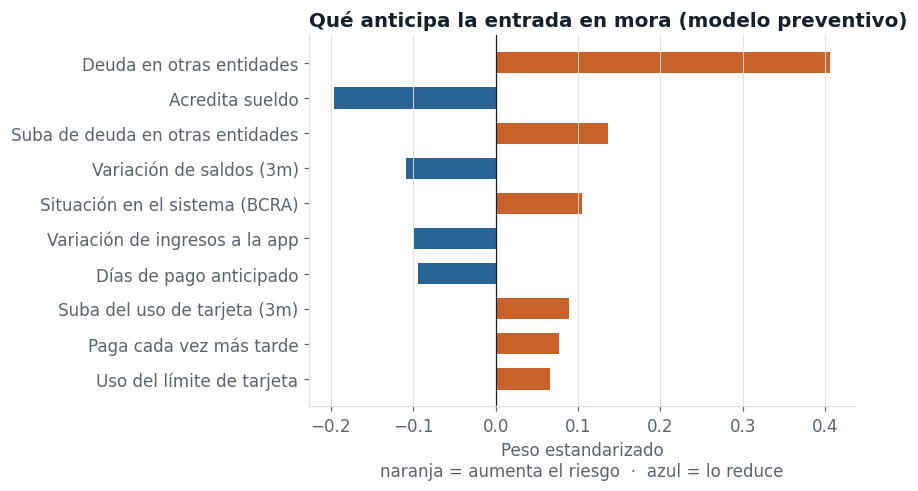

In [8]:
def grafico_pesos(modelo, variables, titulo, archivo, n=10):
    coef = pd.Series(modelo[-1].coef_[0], index=variables)
    top = coef.reindex(coef.abs().sort_values(ascending=False).index[:n])[::-1]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.barh([NOMBRES[v] for v in top.index], top.values, color=[NARANJA if v > 0 else AZUL for v in top.values], height=0.6)
    ax.axvline(0, color=TINTA, lw=0.8); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Peso estandarizado\nnaranja = aumenta el riesgo  ·  azul = lo reduce")
    ax.set_title(titulo)
    plt.tight_layout(); plt.savefig(IMG / archivo); plt.show()

grafico_pesos(log_prev, VARS_PREV, "Qué anticipa la entrada en mora (modelo preventivo)", "03_pesos_preventivo.png")

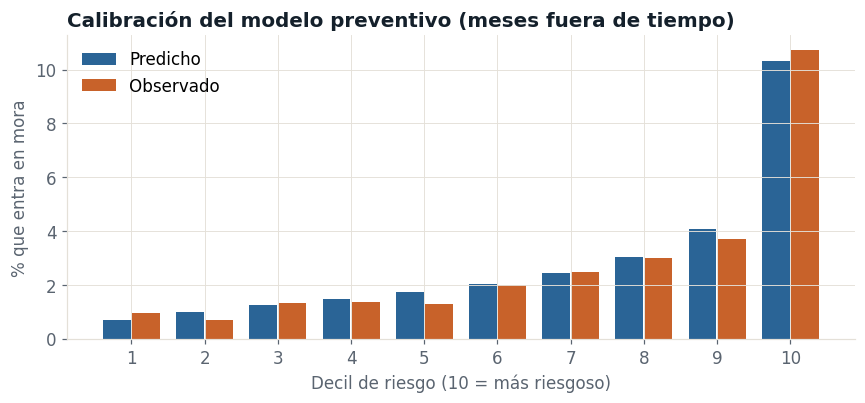

El decil más riesgoso concentra una tasa de entrada 3.9 veces la media


In [9]:
# Calibración: si el modelo dice 10%, ¿entra efectivamente el 10%?
o = oot(prev).copy(); o["p"] = log_prev.predict_proba(o[VARS_PREV].fillna(0))[:, 1]
o["decil"] = pd.qcut(o.p.rank(method="first"), 10, labels=range(1, 11))
cal = o.groupby("decil").agg(predicho=("p", "mean"), observado=("entra_mora", "mean")) * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(1, 11)
ax.bar(x - 0.2, cal.predicho, width=0.38, color=AZUL, label="Predicho")
ax.bar(x + 0.2, cal.observado, width=0.38, color=NARANJA, label="Observado")
ax.set_xticks(x); ax.set_xlabel("Decil de riesgo (10 = más riesgoso)"); ax.set_ylabel("% que entra en mora")
ax.set_title("Calibración del modelo preventivo (meses fuera de tiempo)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(IMG / "04_calibracion_preventivo.png"); plt.show()
print(f"El decil más riesgoso concentra una tasa de entrada {cal.observado.iloc[-1]/ (o.entra_mora.mean()*100):.1f} veces la media")

## 5. Modelo temprano: ¿quién va a rolear y quién se cura solo?

Para clientes en mora de 1 a 90 días entrenamos dos modelos:

- **Roleo:** probabilidad de pasar al tramo siguiente → dónde tiene que estar el gestor.
- **Self-cure:** probabilidad de regularizarse sin intervención → a quién alcanza con un recordatorio digital.

In [10]:
log_roll, gbm_roll, tabla_roll = entrenar(temp, VARS_TEMP, "rolea")
log_cura, gbm_cura, tabla_cura = entrenar(temp, VARS_TEMP, "se_cura")
pd.concat({"Roleo": tabla_roll, "Self-cure": tabla_cura})

AUC   Gini     KS
Roleo     Logística · entrenamiento    0.810  0.620  0.469
          Logística · fuera de tiempo  0.793  0.586  0.444
          LightGBM · fuera de tiempo   0.789  0.578  0.447
Self-cure Logística · entrenamiento    0.814  0.627  0.487
          Logística · fuera de tiempo  0.801  0.602  0.466
          LightGBM · fuera de tiempo   0.802  0.603  0.479

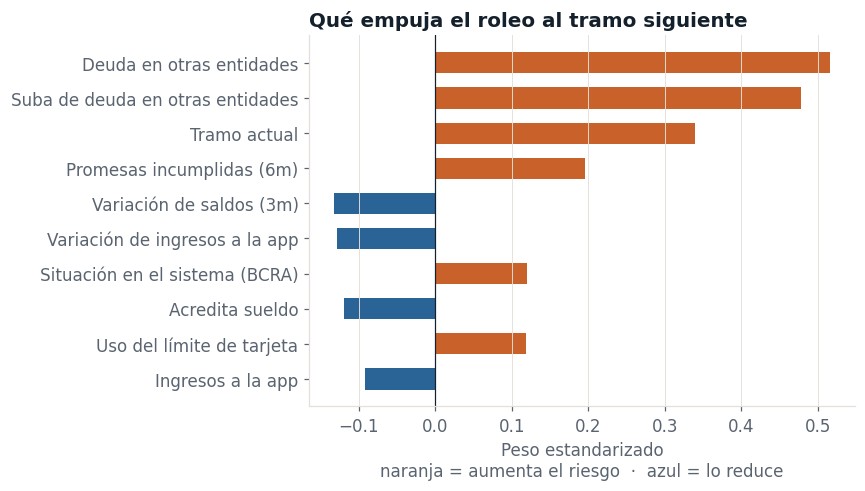

In [11]:
grafico_pesos(log_roll, VARS_TEMP, "Qué empuja el roleo al tramo siguiente", "05_pesos_roleo.png")

**Decisión: usamos la regresión logística en producción.** El retador LightGBM no mejora de forma relevante
(ver tablas), y la logística se puede explicar variable por variable: cada gestor recibe el *motivo* de cada caso.
Si en datos reales el retador ganara por varios puntos de Gini, se evaluaría el cambio con herramientas de
explicabilidad (SHAP) antes de adoptarlo.

## 6. De probabilidad a pesos: pérdida esperada

Pérdida esperada = **PD × LGD × EAD**

- **PD a 12 meses por tramo:** se calcula elevando la matriz de transición a la potencia 12 (cadena de Markov):
  probabilidad de terminar en 90+ dentro de un año partiendo de cada tramo.
- **LGD:** 55% (supuesto para consumo sin garantía).
- **EAD:** la exposición del cliente (préstamo + tarjeta).

El **valor en juego** de cada cliente es cuánto empeora la pérdida esperada si pasa al tramo siguiente,
multiplicado por la probabilidad de que eso pase.

In [12]:
LGD = 0.55
M12 = np.linalg.matrix_power(M.values, 12)
PD = pd.Series(M12[:, 4], index=range(5))
print("PD a 12 meses por tramo:", {TRAMOS[k]: f"{PD[k]:.1%}" for k in range(4)})

def puntuar(d):
    d = d.copy()
    d["p_entra"] = np.where(d.tramo == 0, log_prev.predict_proba(d[VARS_PREV].fillna(0))[:, 1], np.nan)
    d["p_roll"] = np.where(d.tramo.between(1, 3), log_roll.predict_proba(d[VARS_TEMP].fillna(0))[:, 1], np.nan)
    d["p_cura"] = np.where(d.tramo.between(1, 3), log_cura.predict_proba(d[VARS_TEMP].fillna(0))[:, 1], np.nan)
    d["p_evento"] = np.where(d.tramo == 0, d.p_entra, d.p_roll)
    d["salto_pd"] = d.tramo.map(lambda k: PD[min(k + 1, 4)] - PD[k])
    d["perdida_si_ocurre"] = d.exposicion * LGD * d.salto_pd
    d["valor_en_juego"] = d.p_evento * d.perdida_si_ocurre
    return d

PD a 12 meses por tramo: {'Al día': '4.4%', '1-30': '23.8%', '31-60': '61.0%', '61-90': '86.9%'}


## 7. Estrategia y backtest contra la gestión tradicional

Mismo equipo, misma capacidad: **350 contactos de gestor por mes**. Comparamos dos formas de usarla en un mes
fuera de tiempo, donde ya sabemos qué pasó después.

| | Gestión tradicional | Estrategia "Llegar antes" |
|---|---|---|
| Gestor humano | Clientes en mora, del más atrasado al menos atrasado | Mayor valor en juego, incluidos clientes al día en riesgo |
| Canal digital | Resto de la mora (recordatorio genérico) | Clientes con alta probabilidad de self-cure + preventivo al 10% de clientes al día más riesgosos + resto de la mora |
| Clientes al día | Sin contacto | Contacto preventivo según riesgo |

**Supuestos de efectividad** (explícitos y ajustables): el contacto de un gestor reduce 30% la probabilidad del
evento (roleo o entrada en mora); el digital, 10%. Costo por contacto: gestor $ 6.000, digital $ 150.

In [13]:
CAPACIDAD, EF_GESTOR, EF_DIGITAL, COSTO_GESTOR, COSTO_DIGITAL = 350, 0.30, 0.10, 6_000, 150
UMBRAL_CURA = 0.60

def asignar(d, estrategia):
    d = d.copy(); d["canal"] = "Sin contacto"
    mora = d.tramo.between(1, 3)
    if estrategia == "Tradicional":
        orden = d[mora].sort_values("dias_atraso", ascending=False).index
        d.loc[orden[:CAPACIDAD], "canal"] = "Gestor"
        d.loc[orden[CAPACIDAD:], "canal"] = "Digital"
    else:
        autocura = mora & (d.p_cura >= UMBRAL_CURA) & (d.tramo == 1)
        candidatos = d[~autocura & (mora | (d.tramo == 0))].sort_values("valor_en_juego", ascending=False).index
        d.loc[candidatos[:CAPACIDAD], "canal"] = "Gestor"
        corte_prev = d.loc[d.tramo == 0, "p_entra"].quantile(0.90)
        prev_digital = (d.tramo == 0) & (d.p_entra >= corte_prev) & (d.canal == "Sin contacto")
        d.loc[(mora & (d.canal == "Sin contacto")) | prev_digital, "canal"] = "Digital"
    return d

def evaluar(d):
    evento = np.where(d.tramo == 0, d.entra_mora, d.rolea) == 1
    perdida_real = np.where(evento, d.perdida_si_ocurre, 0)   # pérdida esperada generada por quienes efectivamente rolearon/entraron
    ef = d.canal.map({"Gestor": EF_GESTOR, "Digital": EF_DIGITAL, "Sin contacto": 0}).values
    contactados = d.canal != "Sin contacto"
    return {
        "Contactos de gestor": int((d.canal == "Gestor").sum()),
        "Contactos digitales": int((d.canal == "Digital").sum()),
        "% de la gestión sin intervención humana": (d.canal == "Digital").sum() / contactados.sum(),
        "% de la pérdida generada que pasó por un gestor": perdida_real[d.canal == "Gestor"].sum() / perdida_real.sum(),
        "Pérdida esperada evitada ($)": (ef * perdida_real).sum(),
        "Costo de gestión ($)": (d.canal == "Gestor").sum() * COSTO_GESTOR + (d.canal == "Digital").sum() * COSTO_DIGITAL,
    }

MES_BT = 16
mes_bt = puntuar(base[(base.mes_idx == MES_BT) & base.tramo.between(0, 3)])
res = {e: evaluar(asignar(mes_bt, e)) for e in ["Tradicional", "Llegar antes"]}
res = pd.DataFrame(res)
res.loc["Pesos evitados por peso de gestión"] = res.loc["Pérdida esperada evitada ($)"] / res.loc["Costo de gestión ($)"]
mejora = res.loc["Pérdida esperada evitada ($)", "Llegar antes"] / res.loc["Pérdida esperada evitada ($)", "Tradicional"] - 1
print(f"Mes evaluado: {mes_bt.mes.iloc[0]} (resultado observado en el mes siguiente)")
res.style.format(lambda v: f"{v:.1%}" if abs(v) < 1 else (f"{v:,.1f}" if v < 100 else f"{v:,.0f}"))

Mes evaluado: 2026-08 (resultado observado en el mes siguiente)


,Tradicional,Llegar antes
Contactos de gestor,350,350
Contactos digitales,297,"1,353"
% de la gestión sin intervención humana,45.9%,79.4%
% de la pérdida generada que pasó por un gestor,29.1%,49.3%
Pérdida esperada evitada ($),"35,256,907","53,970,043"
Costo de gestión ($),"2,144,550","2,302,950"
Pesos evitados por peso de gestión,16.4,23.4


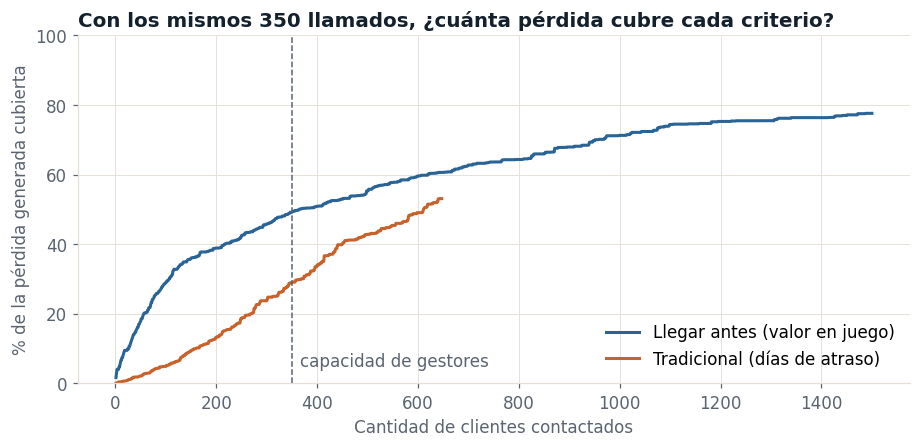

Con 350 llamados: Llegar antes cubre 49% de la pérdida generada; tradicional 29%


In [14]:
# Curva de captura: ordenando por cada criterio, ¿qué % de la pérdida generada cubrimos con los primeros N contactos?
d = mes_bt.copy()
d["evento"] = np.where(d.tramo == 0, d.entra_mora, d.rolea)
d["perdida_real"] = d.evento * d.perdida_si_ocurre
tot = d.perdida_real.sum()
mod = d.sort_values("valor_en_juego", ascending=False).perdida_real.cumsum().values / tot
tra = d[d.tramo >= 1].sort_values("dias_atraso", ascending=False).perdida_real.cumsum().values / tot
n = 1500
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(range(1, n + 1), mod[:n] * 100, color=AZUL, lw=2, label="Llegar antes (valor en juego)")
ax.plot(range(1, min(n, len(tra)) + 1), tra[:n] * 100, color=NARANJA, lw=2, label="Tradicional (días de atraso)")
ax.axvline(CAPACIDAD, color=GRIS, lw=1, ls="--"); ax.text(CAPACIDAD + 15, 5, "capacidad de gestores", color=GRIS)
ax.set_xlabel("Cantidad de clientes contactados"); ax.set_ylabel("% de la pérdida generada cubierta")
ax.set_ylim(0, 100); ax.set_title("Con los mismos 350 llamados, ¿cuánta pérdida cubre cada criterio?")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(IMG / "06_curva_captura.png"); plt.show()
cap_mod, cap_tra = mod[CAPACIDAD - 1], tra[CAPACIDAD - 1]
print(f"Con {CAPACIDAD} llamados: Llegar antes cubre {cap_mod:.0%} de la pérdida generada; tradicional {cap_tra:.0%}")

## 8. Lista priorizada del próximo mes

Con los datos del último mes disponible se genera la lista operativa: cada cliente con su canal, su prioridad
y el **motivo principal** en lenguaje de negocio (las variables que más empujan su riesgo según el modelo).
Esta tabla es la que, en la siguiente etapa, recibe el flujo de n8n para disparar mensajes y alertas.

In [15]:
def motivos(d, modelo, variables, n=2):
    z = (d[variables].fillna(0) - modelo[0].mean_) / modelo[0].scale_
    contrib = z * modelo[-1].coef_[0]
    top = contrib.apply(lambda fila: [NOMBRES[v] for v in fila.sort_values(ascending=False).index[:n] if fila[v] > 0], axis=1)
    return top.str.join(" · ")

ultimo = p[(p.mes_idx == p.mes_idx.max()) & p.tramo.between(0, 3)]
lista = asignar(puntuar(ultimo), "Llegar antes")
lista["motivo_principal"] = ""
m0, m1 = lista.tramo == 0, lista.tramo >= 1
lista.loc[m0, "motivo_principal"] = motivos(lista[m0], log_prev, VARS_PREV)
lista.loc[m1, "motivo_principal"] = motivos(lista[m1], log_roll, VARS_TEMP)
lista = lista[lista.canal != "Sin contacto"].sort_values("valor_en_juego", ascending=False)
lista["prioridad"] = range(1, len(lista) + 1)
lista["tramo"] = lista.tramo.map(TRAMOS)
cols = ["prioridad", "cliente_id", "segmento", "tramo", "dias_atraso", "exposicion", "p_entra", "p_roll", "p_cura",
        "valor_en_juego", "canal", "motivo_principal"]
lista[cols].round(3).to_csv(OUT / "lista_priorizada.csv", index=False)
print(f"Lista para el mes siguiente a {ultimo.mes.iloc[0]}: {len(lista):,} clientes ({(lista.canal=='Gestor').sum()} a gestor)")
lista[cols].head(10).round(3)

Lista para el mes siguiente a 2026-09: 1,729 clientes (350 a gestor)


,prioridad,cliente_id,segmento,tramo,dias_atraso,exposicion,p_entra,p_roll,p_cura,valor_en_juego,canal,motivo_principal
12851,1,BA000714,Premium,31-60,59,25964500.0,NaN,0.955,0.006,3521232.285,Gestor,Suba de deuda en otras entidades · Deuda en ot...
103589,2,BA005755,Plus,1-30,10,17879700.0,NaN,0.673,0.081,2467756.491,Gestor,Suba de deuda en otras entidades · Deuda en ot...
44261,3,BA002459,Plus,1-30,10,15085900.0,NaN,0.703,0.093,2175216.872,Gestor,Suba de deuda en otras entidades · Deuda en ot...
111671,4,BA006204,Premium,1-30,8,16918200.0,NaN,0.582,0.124,2018165.034,Gestor,Suba de deuda en otras entidades · Situación e...
50867,5,BA002826,Plus,1-30,7,11257900.0,NaN,0.829,0.038,1913319.585,Gestor,Suba de deuda en otras entidades · Deuda en ot...
78425,6,BA004357,Premium,31-60,51,18411700.0,NaN,0.719,0.062,1880399.986,Gestor,Deuda en otras entidades · Tramo actual
182051,7,BA010114,Premium,1-30,12,23851300.0,NaN,0.374,0.240,1828716.307,Gestor,Situación en el sistema (BCRA) · Segmento Premium
165671,8,BA009204,Premium,61-90,66,30811200.0,NaN,0.779,0.028,1733758.991,Gestor,Deuda en otras entidades · Promesas incumplida...
204965,9,BA011387,Plus,31-60,33,10469900.0,NaN,0.984,0.002,1463542.576,Gestor,Suba de deuda en otras entidades · Deuda en ot...
65987,10,BA003666,Premium,1-30,28,15125400.0,NaN,0.457,0.240,1417590.173,Gestor,Deuda en otras entidades · Variación de saldos...


In [16]:
# Tablas para los tableros (Looker Studio / Power BI / Tableau) y cifras clave para la portada
tr = p[p.tramo_sig.notna() & p.tramo.between(0, 3)]
tr = tr.assign(_roll=(tr.tramo_sig > tr.tramo).astype(int), _cura=np.where(tr.tramo > 0, (tr.tramo_sig == 0).astype(float), np.nan))
rr = tr.groupby(["mes", "tramo"]).agg(clientes=("cliente_id", "size"), roll_rate=("_roll", "mean"),
                                       cura=("_cura", "mean"), saldo=("exposicion", "sum")).reset_index()
rr["tramo"] = rr.tramo.map(TRAMOS)
rr.to_csv(OUT / "roll_rates_mensual.csv", index=False)

r = res["Llegar antes"]; t = res["Tradicional"]
clave = {
    "mes_backtest": str(mes_bt.mes.iloc[0]),
    "capacidad_gestor": CAPACIDAD,
    "gini_preventivo_oot": float(tabla_prev.loc["Logística · fuera de tiempo", "Gini"]),
    "gini_roleo_oot": float(tabla_roll.loc["Logística · fuera de tiempo", "Gini"]),
    "gini_cura_oot": float(tabla_cura.loc["Logística · fuera de tiempo", "Gini"]),
    "perdida_evitada_tradicional": float(t["Pérdida esperada evitada ($)"]),
    "perdida_evitada_modelo": float(r["Pérdida esperada evitada ($)"]),
    "mejora_perdida_evitada": float(mejora),
    "captura_350_modelo": float(cap_mod), "captura_350_tradicional": float(cap_tra),
    "pct_sin_humano_modelo": float(r["% de la gestión sin intervención humana"]),
    "pct_sin_humano_tradicional": float(t["% de la gestión sin intervención humana"]),
    "roll_rates": {k: float(v) for k, v in roll.items()},
    "pd12": {TRAMOS[k]: float(PD[k]) for k in range(4)},
}
(OUT / "resultados_clave.json").write_text(json.dumps(clave, indent=2, ensure_ascii=False))
clave

{'mes_backtest': '2026-08',
 'capacidad_gestor': 350,
 'gini_preventivo_oot': 0.468,
 'gini_roleo_oot': 0.586,
 'gini_cura_oot': 0.602,
 'perdida_evitada_tradicional': 35256906.85104722,
 'perdida_evitada_modelo': 53970043.49789178,
 'mejora_perdida_evitada': 0.530765127125403,
 'captura_350_modelo': 0.49275334930254894,
 'captura_350_tradicional': 0.2905560424210833,
 'pct_sin_humano_modelo': 0.7944803288314739,
 'pct_sin_humano_tradicional': 0.45904173106646057,
 'roll_rates': {'Al día': 0.027781904620413016,
  '1-30': 0.26148303812668866,
  '31-60': 0.49434571890145396,
  '61-90': 0.5976744186046512},
 'pd12': {'Al día': 0.04351756233445806,
  '1-30': 0.2377814878435324,
  '31-60': 0.6104487691293066,
  '61-90': 0.8687194764230688}}

## 9. Conclusiones y limitaciones

**Conclusiones** (ver cifras en `resultados_clave.json`):

- Las señales de comportamiento —corte de sueldo, caída de saldos, uso creciente de la tarjeta, deuda en otras
  entidades— anticipan la mora **antes** de que aparezca el primer día de atraso.
- Ordenar la gestión por **valor en juego** en lugar de por días de atraso cubre mucha más pérdida con la
  misma capacidad de gestores.
- Derivar a canal digital a quien se cura solo libera horas de gestor para los casos que lo necesitan.

**Limitaciones (dichas con honestidad):**

- Los datos son sintéticos: las relaciones entre variables las define el simulador. En datos reales las
  métricas serán distintas y hay que recalibrar.
- La efectividad de cada canal es un **supuesto**. En producción se mide con un **grupo de control**
  (clientes similares sin la acción) antes de escalar.
- Los datos históricos no registran qué contacto recibió cada cliente; con datos reales habría que separar
  el efecto de la gestión pasada.
- La LGD es fija por supuesto; un modelo de LGD por producto y tramo mejoraría la estimación.

**Próximos pasos:** flujo en n8n que lee la lista priorizada y dispara mensajes y alertas; tablero de roll
rates en Looker Studio; Plan Anticipa (refinanciación preventiva) para el segmento preventivo de alto valor.